In [5]:
"""
Bank Marketing Campaign - Classifier Comparison Pipeline
Dataset: UCI Bank Marketing (bank-additional.csv)
Algorithms: Logistic Regression, K-Nearest Neighbors, Decision Trees, SVM
"""

'\nBank Marketing Campaign - Classifier Comparison Pipeline\nDataset: UCI Bank Marketing (bank-additional.csv)\nAlgorithms: Logistic Regression, K-Nearest Neighbors, Decision Trees, SVM\n'

In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, RocCurveDisplay
)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [9]:
# ==============================================================================
# 1. DATA INGESTION & DATA LEAKAGE MITIGATION
# ==============================================================================
print("[*] Loading data...")
# UCI bank-additional-full dataset typically uses ';' as the delimiter
data_path = '../data/bank-additional.csv'
df = pd.read_csv(data_path, sep=';')

[*] Loading data...


In [10]:
# CRITICAL LEAKAGE CHECK:
# As noted by UCI documentation, 'duration' heavily leaks the target since a call
# duration is unknown before calling. We drop 'duration' for realistic deployment.
feature_cols = [col for col in df.columns if col not in ['y', 'duration']]

In [11]:
X = df[feature_cols].copy()
y = df['y'].map({'yes': 1, 'no': 0}).astype(int)

In [12]:
# 80/20 Stratified Split to preserve minority class proportion (~11.3%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [13]:
# Identify numerical and categorical feature sets
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

C:\Users\Vishesh Grover\AppData\Local\Temp\ipykernel_3488\2712295194.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns.tolist()


In [14]:
print(f"Features: {len(num_cols)} numerical, {len(cat_cols)} categorical.")
print(f"Training set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")

Features: 9 numerical, 10 categorical.
Training set: 3295 samples | Test set: 824 samples


In [15]:
# ==============================================================================
# 2. PREPROCESSING PIPELINE SETUP
# ==============================================================================
# StandardScaler handles numerical scaling (vital for KNN, SVM, Logistic Regression)
# OneHotEncoder transforms nominal variables, dropping first level to prevent collinearity
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

In [16]:
# ==============================================================================
# 3. BASELINE MODELS COMPARISON
# ==============================================================================
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    # Pre-tune sample or probability config for SVM speed:
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42)
}

In [17]:
baseline_results = []

In [18]:
print("\n[*] Training Baseline Models...")
for name, clf in baseline_models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

    start_time = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - start_time

    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)

    # Extract prediction probabilities for ROC-AUC
    if hasattr(pipe.named_steps['classifier'], 'predict_proba'):
        y_test_proba = pipe.predict_proba(X_test)[:, 1]
    else:
        y_test_proba = pipe.decision_function(X_test)

    baseline_results.append({
        'Model': name,
        'Train Time (s)': round(train_time, 3),
        'Train Accuracy': round(accuracy_score(y_train, y_train_pred), 4),
        'Test Accuracy': round(accuracy_score(y_test, y_test_pred), 4),
        'Test Recall': round(recall_score(y_test, y_test_pred), 4),
        'Test F1': round(f1_score(y_test, y_test_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_test_proba), 4)
    })


[*] Training Baseline Models...


C:\Users\Vishesh Grover\Desktop\New folder\New folder\bank-marketing-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [19]:
df_baseline = pd.DataFrame(baseline_results)
print("\n--- Baseline Performance Summary ---")
print(df_baseline.to_string(index=False))


--- Baseline Performance Summary ---
                 Model  Train Time (s)  Train Accuracy  Test Accuracy  Test Recall  Test F1  Test ROC-AUC
   Logistic Regression           0.054          0.9056         0.9017       0.1778   0.2832        0.7723
   K-Nearest Neighbors           0.017          0.9099         0.8871       0.1444   0.2185        0.6739
         Decision Tree           0.039          1.0000         0.8422       0.2889   0.2857        0.5995
Support Vector Machine           1.197          0.9108         0.8981       0.1000   0.1765        0.6774


In [20]:
# ==============================================================================
# 4. HYPERPARAMETER OPTIMIZATION (GridSearchCV)
# ==============================================================================
# Stratified 5-Fold Cross-Validation targeting ROC-AUC (better suited for imbalance)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [21]:
param_grids = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'classifier__C': [0.01, 0.1, 1.0, 10.0],
            'classifier__solver': ['lbfgs']
        }
    },
    'K-Nearest Neighbors': {
        'model': KNeighborsClassifier(),
        'params': {
            'classifier__n_neighbors': [7, 15, 25],
            'classifier__weights': ['uniform', 'distance']
        }
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'classifier__max_depth': [4, 6, 8, 10],
            'classifier__min_samples_split': [10, 30, 50],
            'classifier__criterion': ['gini', 'entropy']
        }
    },
    'Support Vector Machine': {
        'model': SVC(kernel='rbf', probability=True, random_state=42),
        'params': {
            'classifier__C': [0.5, 1.0, 5.0],
            'classifier__gamma': ['scale', 'auto']
        }
    }
}

In [22]:
tuned_results = []
best_estimators = {}

In [23]:
print("\n[*] Starting Hyperparameter Optimization across all 4 models...")
for name, config in param_grids.items():
    print(f"  -> Tuning {name}...")
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', config['model'])
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=config['params'],
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )

    start_time = time.time()
    grid.fit(X_train, y_train)
    fit_time = time.time() - start_time

    best_estimator = grid.best_estimator_
    best_estimators[name] = best_estimator

    y_pred = best_estimator.predict(X_test)
    y_proba = best_estimator.predict_proba(X_test)[:, 1]

    tuned_results.append({
        'Model': name,
        'Best Params': grid.best_params_,
        'Tune Time (s)': round(fit_time, 2),
        'CV ROC-AUC': round(grid.best_score_, 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test Recall': round(recall_score(y_test, y_pred), 4),
        'Test F1': round(f1_score(y_test, y_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    })


[*] Starting Hyperparameter Optimization across all 4 models...
  -> Tuning Logistic Regression...
  -> Tuning K-Nearest Neighbors...
  -> Tuning Decision Tree...
  -> Tuning Support Vector Machine...


C:\Users\Vishesh Grover\Desktop\New folder\New folder\bank-marketing-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [24]:
df_tuned = pd.DataFrame(tuned_results)
print("\n--- Optimized Model Performance Summary ---")
print(df_tuned[['Model', 'CV ROC-AUC', 'Test ROC-AUC', 'Test Recall', 'Test F1']].to_string(index=False))


--- Optimized Model Performance Summary ---
                 Model  CV ROC-AUC  Test ROC-AUC  Test Recall  Test F1
   Logistic Regression      0.7745        0.7923       0.1444   0.2407
   K-Nearest Neighbors      0.7592        0.7061       0.1556   0.2456
         Decision Tree      0.7608        0.7526       0.1444   0.2430
Support Vector Machine      0.7124        0.6644       0.1778   0.2759


In [25]:
# ==============================================================================
# 5. FEATURE INTERPRETABILITY & IMPORTANCE (Rubric Criterion 4)
# ==============================================================================
print("\n[*] Extracting feature importances from tuned models...")


[*] Extracting feature importances from tuned models...


In [26]:
# Extract feature names after One-Hot Encoding transformation
ohe = best_estimators['Logistic Regression'].named_steps['preprocessor'].named_transformers_['cat']
cat_encoded_names = ohe.get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + cat_encoded_names

In [27]:
# 1. Logistic Regression Coefficients
lr_model = best_estimators['Logistic Regression'].named_steps['classifier']
lr_coefs = pd.Series(lr_model.coef_[0], index=all_feature_names).sort_values()

In [28]:
# 2. Decision Tree Feature Importances
dt_model = best_estimators['Decision Tree'].named_steps['classifier']
dt_importances = pd.Series(dt_model.feature_importances_, index=all_feature_names).sort_values(ascending=False)

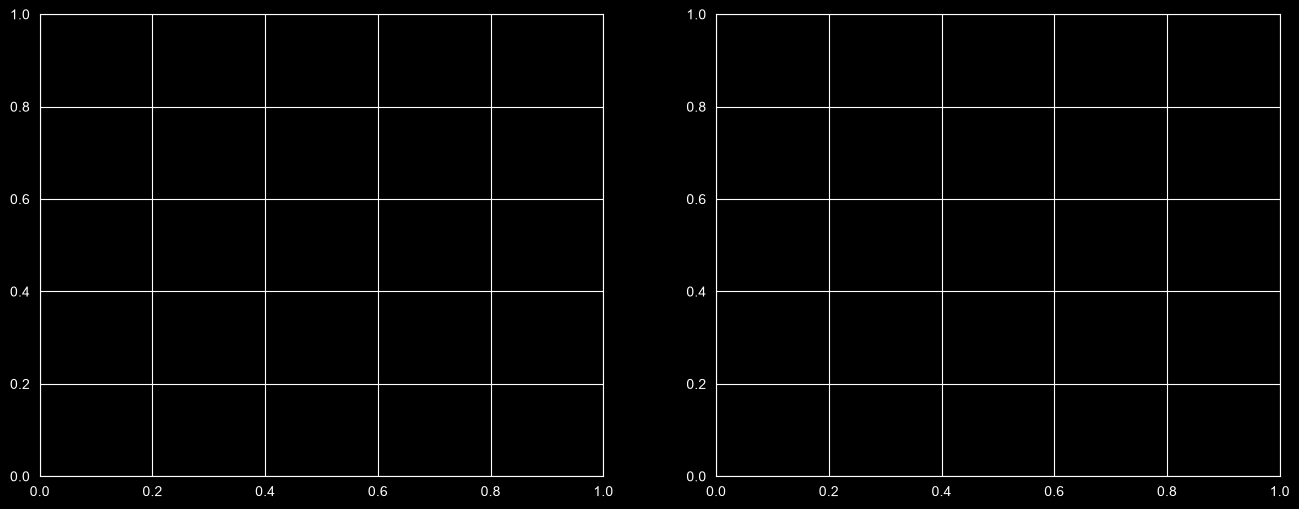

In [29]:
# Visualizing Top Positive/Negative Drivers
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

In [30]:
# Top 10 Coefficients for Logistic Regression
top_lr = pd.concat([lr_coefs.head(5), lr_coefs.tail(5)])
top_lr.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top Logistic Regression Coefficients (Log-Odds Impact)', fontsize=12)
axes[0].set_xlabel('Coefficient Value')

Text(0.5, 4.444444444444455, 'Coefficient Value')

In [31]:
# Top 10 Features for Decision Tree
dt_importances.head(10).plot(kind='barh', ax=axes[1], color='darkseagreen')
axes[1].set_title('Top 10 Feature Importances (Decision Tree)', fontsize=12)
axes[1].set_xlabel('Gini Importance')
axes[1].invert_yaxis()

In [32]:
plt.tight_layout()
plt.savefig('../visuals/feature_importance.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

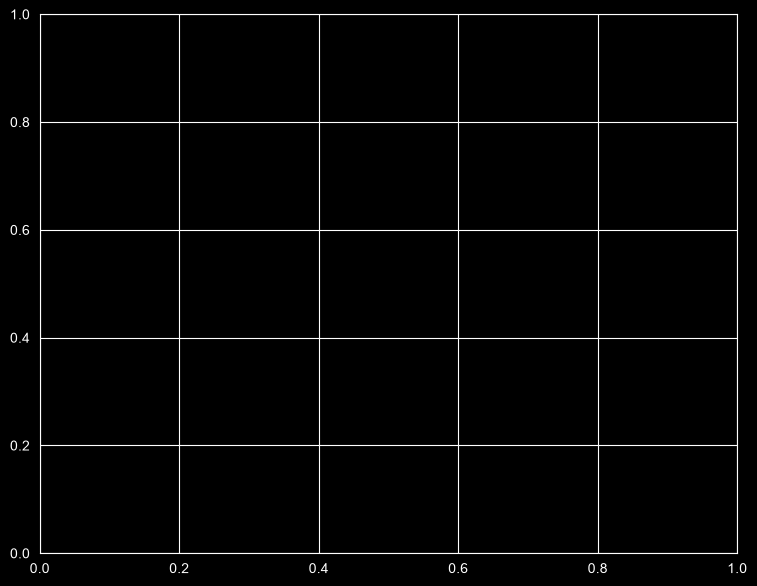

In [33]:
# ==============================================================================
# 6. COMBINED ROC CURVES (Rubric Criterion 3)
# ==============================================================================
plt.figure(figsize=(9, 7))
ax = plt.gca()

In [34]:
for name, estimator in best_estimators.items():
    RocCurveDisplay.from_estimator(estimator, X_test, y_test, name=name, ax=ax)

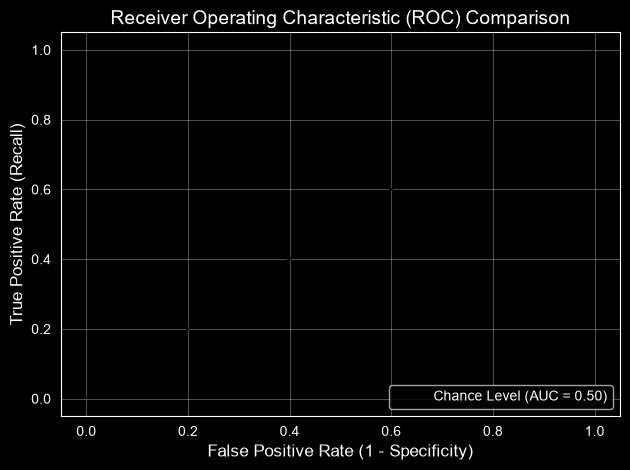

In [35]:
plt.plot([0, 1], [0, 1], 'k--', label='Chance Level (AUC = 0.50)')
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontsize=14)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.grid(alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../visuals/model_comparison_table.png', dpi=300)
plt.show()

In [36]:
print("\nPipeline execution complete. Plots saved to 'visuals/' directory.")


Pipeline execution complete. Plots saved to 'visuals/' directory.
